# **Klasifikasi Deteksi Status Kantuk Menggunakan SVM**


## **1.0 Busines Understanding**

### **1.1 Latar Belakang**
Sebuah lembaga ingin membangun sistem untuk mendeteksi tingkat kelelahan dan status kantuk pengemudi secara otomatis.

### **1.2 Tujuan**
Tujuannya yaitu untuk membangun model machine learning untuk mendeteksi tingkat kelelahan dan status kantuk secara otomatis.


### **1.3 Masalah**
Dalam proses observasi, masih dilakukan dengan cara manual sehingga membutuhkan waktu yang lama dalam proses observasi.

### **1.4 Solusi**
Solusinya yaitu membangun model machine learning berbasis SVM untuk mendeteksi tingkat kelelahan dari gelombang otak dan  biologis mata.

### **1.5 Dataset**

**Ukuran Data: 1000 baris (mewakili 1000 sampel rekaman sensor) dan 3 kolom**

**Fitur Input (X): Kolom atribut pengukuran fisiologis, yang meliputi:**
- Tingkat Theta: Aktivitas gelombang otak theta (Theta wave power) yang
berkaitan dengan kondisi relaksasi dan kantuk (satuan: μV ).
2
- Indeks Kedipan Mata: Frekuensi dan durasi rata-rata kedipan kelopak mata
(Eye blink index) per menit.

**Target Label (Y): Kolom Status Kantuk di bagian akhir yang berisi data kategori (string / biner):**
- "Tidak Mengantuk" (Kondisi waspada / terjaga).
- "Mengantuk" (Kondisi kelelahan / penurunan konsentrasi).

## **2.0 Data Preparation**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tkinter as tk

In [2]:
# df = pd.read_csv('mengantuk.csv')
df = pd.read_csv('../dataset/mengantuk.csv')
df.head(10)

,Tingkat Theta,Indeks Kedipan Mata,Status Kantuk
0,4.16,21.75,Tidak Mengantuk
1,13.00,15.87,Mengantuk
2,7.45,14.09,Mengantuk
3,10.69,15.83,Mengantuk
4,9.28,23.36,Mengantuk
5,11.59,17.98,Mengantuk
6,10.81,16.02,Mengantuk
7,2.88,25.43,Tidak Mengantuk
8,7.70,14.21,Mengantuk
9,2.42,27.60,Tidak Mengantuk


In [3]:
df.info()
df.size

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Tingkat Theta        1000 non-null   float64
 1   Indeks Kedipan Mata  1000 non-null   float64
 2   Status Kantuk        1000 non-null   str    
dtypes: float64(2), str(1)
memory usage: 23.6 KB


3000

In [4]:
df.describe()

,Tingkat Theta,Indeks Kedipan Mata
count,1000.000000,1000.000000
mean,6.126480,20.604060
std,4.107107,4.025573
min,-3.990000,11.090000
25%,2.530000,17.145000
50%,6.205000,20.780000
75%,9.730000,24.070000
max,14.930000,31.720000


In [5]:
df.isna().sum()

Tingkat Theta          0
Indeks Kedipan Mata    0
Status Kantuk          0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)


## **3.0 Exploratory Data Analysis**

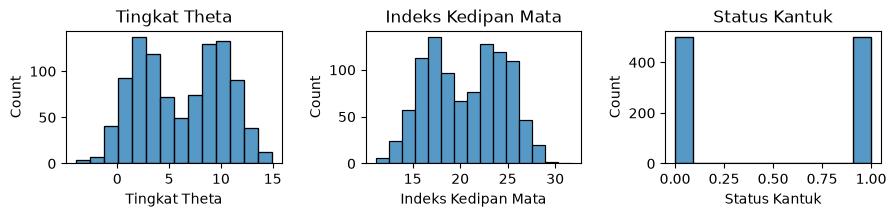

In [35]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(15, 10))

for i, col in enumerate(cols, start=1):
    plt.subplot(5, 5, i)
    sns.histplot(df[col])
    plt.title(col)

plt.tight_layout(h_pad=2, w_pad=2)
plt.show()

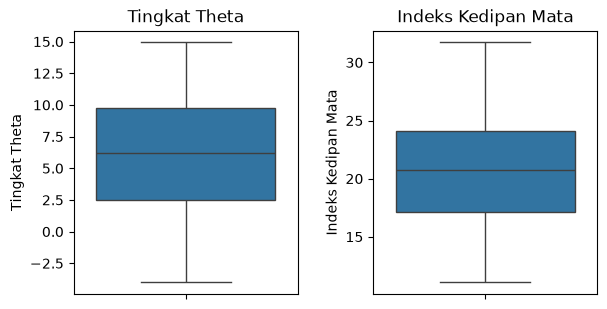

In [11]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(15, 15))

for i, col in enumerate(cols, start=1):
    plt.subplot(5, 5, i)
    sns.boxplot(df[col])
    plt.title(col)

plt.tight_layout(h_pad=2, w_pad=2)
plt.show()

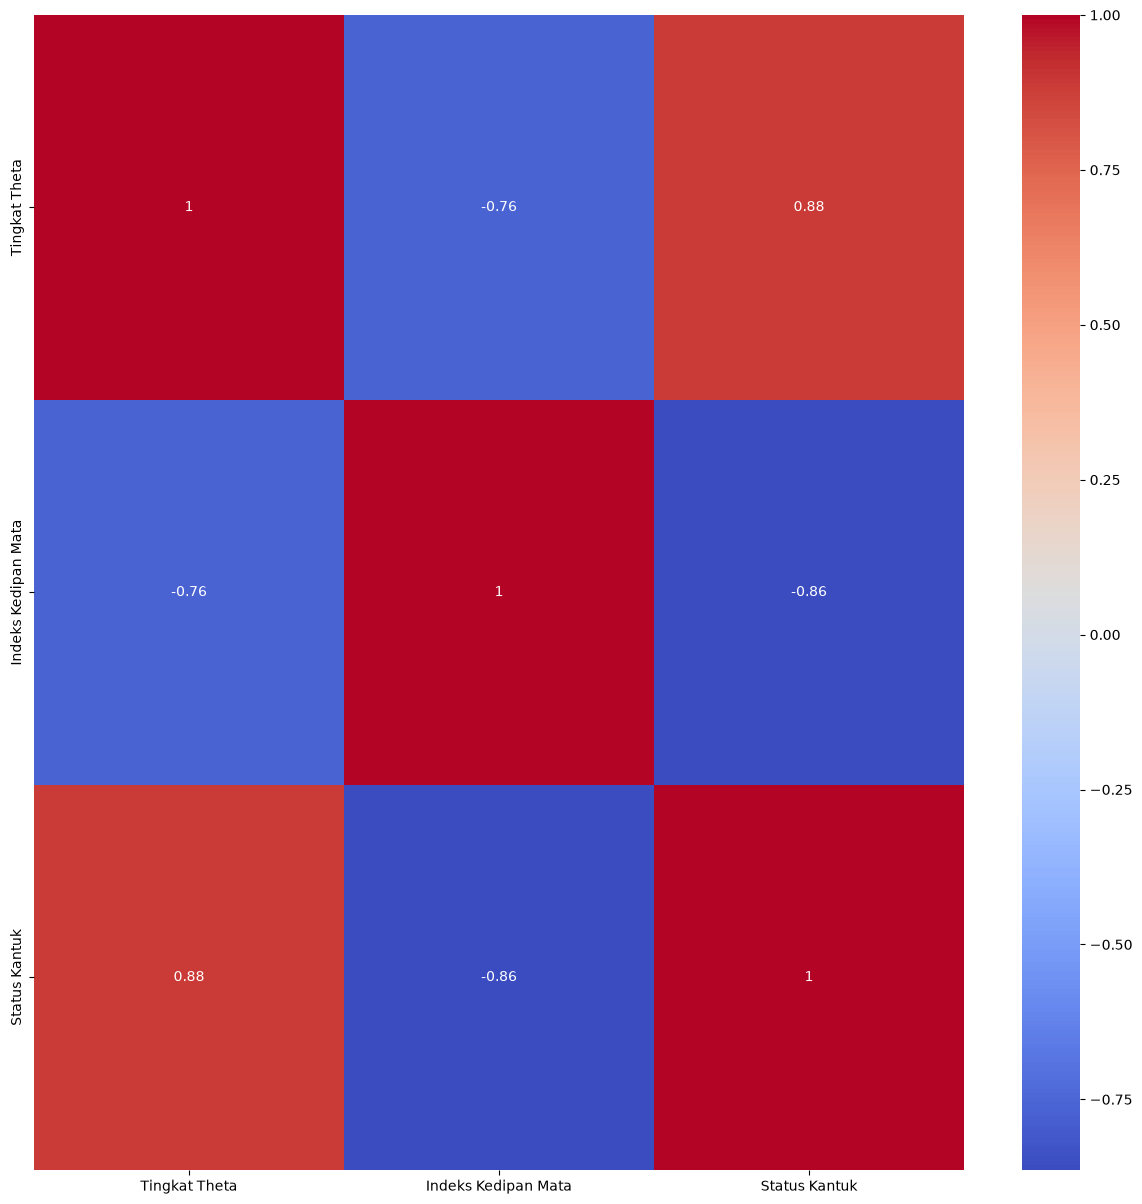

In [34]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(15, 15))
sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm')
plt.show()


In [19]:
q1 = df[cols].quantile(0.25)
q3 = df[cols].quantile(0.75)

iqr = q3 - q1

bb = q1 - 1.5 * iqr
bt = q3 + 1.5 * iqr

outlier = ((df[cols] < bb) | (df[cols] > bt)).sum()

hasil = pd.DataFrame({'Outlier': outlier, 'Persentase': outlier / len(df[cols])})
hasil.sort_values(by='Outlier', ascending=False)


,Outlier,Persentase
Tingkat Theta,0,0.0
Indeks Kedipan Mata,0,0.0


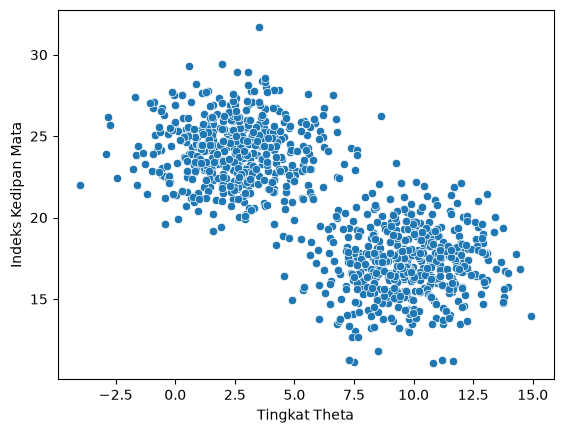

In [20]:
sns.scatterplot(x='Tingkat Theta', y='Indeks Kedipan Mata', data=df)
plt.show()


In [21]:
df['Status Kantuk'] = df['Status Kantuk'].map({'Tidak Mengantuk': 0, 'Mengantuk': 1}) 

In [22]:
df.head(10)

,Tingkat Theta,Indeks Kedipan Mata,Status Kantuk
0,4.16,21.75,0
1,13.00,15.87,1
2,7.45,14.09,1
3,10.69,15.83,1
4,9.28,23.36,1
5,11.59,17.98,1
6,10.81,16.02,1
7,2.88,25.43,0
8,7.70,14.21,1
9,2.42,27.60,0


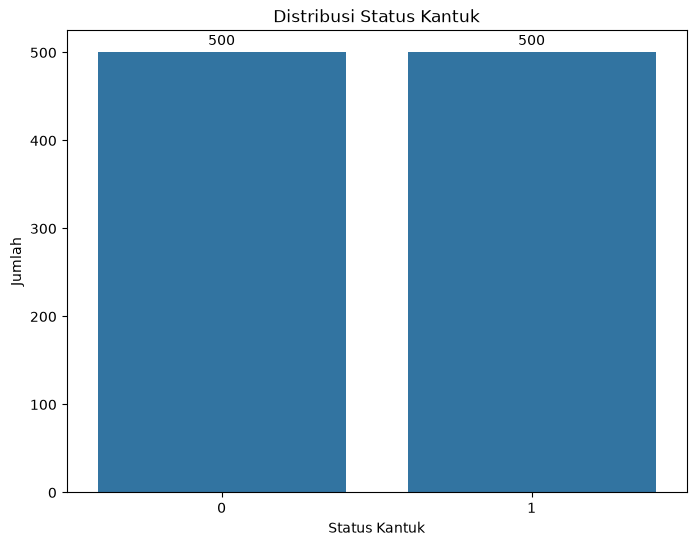

In [33]:
plt.figure(figsize=(8, 6))

ax = sns.countplot(x=df['Status Kantuk'])

plt.title('Distribusi Status Kantuk')
plt.xlabel('Status Kantuk')
plt.ylabel('Jumlah')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.show()